# Pixel Inspector

Este notebook permite hacer click en una imagen para ver qué clase está annotada en ese pixel.

In [1]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape, Polygon
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets
from tqdm import tqdm

In [2]:
DATA = Path("/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data")
DATA_DIR = DATA / "raw"
WSI_DIR = DATA_DIR / "wsi_images"
ANNOT_DIR = DATA_DIR / "annotations_resized"
OUTPUT_DIR = DATA_DIR / "annot_cleanned_test"

# Listar slides disponibles
annot_files = sorted(ANNOT_DIR.glob("slide_*.geojson"))
slide_ids = [f.stem for f in annot_files]
print(f"Slides disponibles: {len(slide_ids)}")
print(slide_ids[:5])

Slides disponibles: 50
['slide_001', 'slide_002', 'slide_003', 'slide_004', 'slide_005']


In [3]:
def load_annotations(annot_path):
    """Carga las anotaciones desde un archivo geojson."""
    with open(annot_path, 'r') as f:
        return geojson.load(f)

def rasterize_all_annotations(annotations, img_shape):
    """Rasteriza todas las clases en una máscara de clases."""
    h, w = img_shape[:2]
    class_mask = np.zeros((h, w), dtype=np.int32)
    
    class_names = []
    for idx, feature in enumerate(annotations['features']):
        class_name = feature['properties'].get('name', 'unknown')
        if class_name not in class_names:
            class_names.append(class_name)
        
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(class_mask, [ext_coords], idx + 1)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(class_mask, [int_coords], 0)
    
    return class_mask, class_names

def get_class_at_pixel(class_mask, class_names, x, y):
    """Devuelve la clase en un pixel específico."""
    if x < 0 or y < 0 or y >= class_mask.shape[0] or x >= class_mask.shape[1]:
        return "fuera de límites"
    
    idx = class_mask[y, x]
    if idx == 0:
        return "sin anotar (background)"
    
    return class_names[idx - 1]

In [4]:
# Cargar slide específico
slide_id = "slide_002"

img_path = WSI_DIR / f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(f"Imagen: {img.shape}")

annot_path = OUTPUT_DIR / f"{slide_id}.geojson"
if not annot_path.exists():
    annot_path = ANNOT_DIR / f"{slide_id}.geojson"
    print(f"Usando anotaciones originales: {annot_path}")
else:
    print(f"Usando anotaciones procesadas: {annot_path}")

annotations = load_annotations(annot_path)
print(f"Features: {len(annotations['features'])}")

Imagen: (4888, 10126, 3)
Usando anotaciones procesadas: /media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annot_cleanned_test/slide_002.geojson
Features: 13


In [5]:
# Rasterizar anotaciones
class_mask, class_names = rasterize_all_annotations(annotations, img.shape)
print(f"Clases encontradas: {class_names}")
print(f"Máscara shape: {class_mask.shape}")
print(f"Valores únicos en mask: {np.unique(class_mask)}")

Clases encontradas: ['Decidua', 'Labyrinth', 'Junctional Zone', 'no_labeled']
Máscara shape: (4888, 10126)
Valores únicos en mask: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]


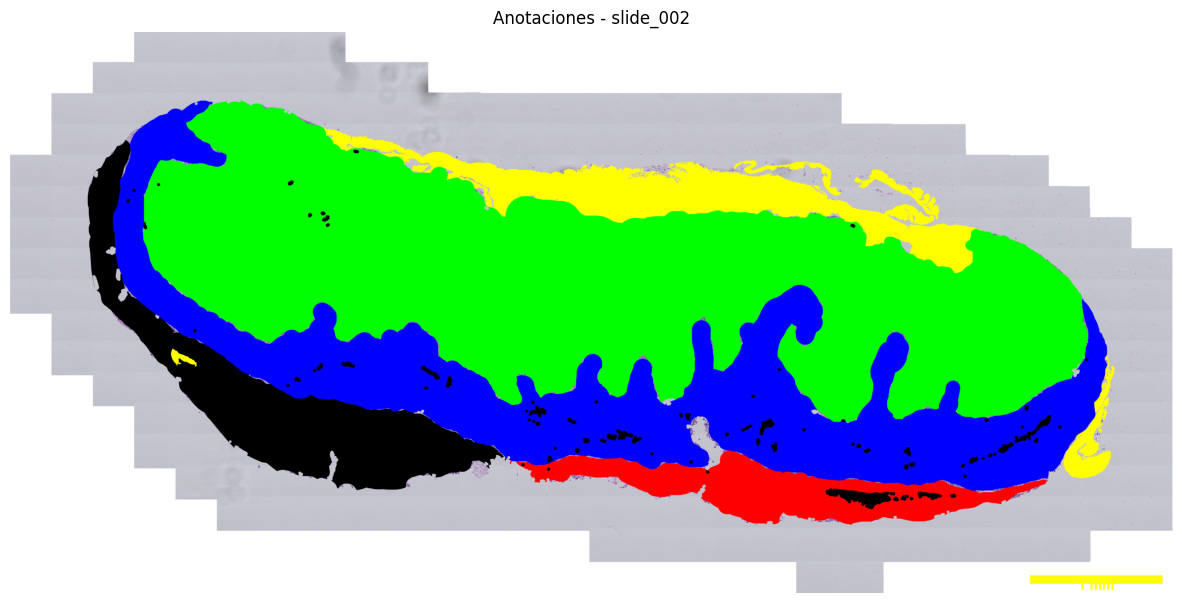

In [6]:
# Mostrar imagen con las clases dibujadas
colors = {
    'Decidua': (255, 0, 0),
    'Labyrinth': (0, 255, 0),
    'Junctional Zone': (0, 0, 255),
    'no_labeled': (255, 255, 0),
    'background': (128, 128, 128)
}

overlay = img_rgb.copy()

# Dibujar todas las features
for idx, feature in enumerate(annotations['features']):
    class_name = feature['properties'].get('name', 'unknown')
    color = colors.get(class_name, (128, 128, 128))
    
    geom = shape(feature['geometry'])
    
    if geom.geom_type == 'Polygon':
        polys = [geom]
    elif geom.geom_type == 'MultiPolygon':
        polys = list(geom.geoms)
    else:
        continue
    
    for poly in polys:
        ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
        cv2.fillPoly(overlay, [ext_coords], color)
        
        for interior in poly.interiors:
            #Supuestamente estos serían "fondos"
            int_coords = np.array(interior.coords, dtype=np.int32)
            cv2.fillPoly(overlay, [int_coords], (0, 0, 0))

plt.figure(figsize=(15, 12))
plt.imshow(overlay)
plt.title(f'Anotaciones - {slide_id}')
plt.axis('off')
plt.show()

In [7]:
# Widgets interactivos para inspeccionar pixels
output = widgets.Output()

x_slider = widgets.IntSlider(description='X:', value=1000, min=0, max=img.shape[1], continuous_update=False)
y_slider = widgets.IntSlider(description='Y:', value=1000, min=0, max=img.shape[0], continuous_update=False)

def update_pixel_info(change):
    x = x_slider.value
    y = y_slider.value
    clase = get_class_at_pixel(class_mask, class_names, x, y)
    with output:
        clear_output(wait=True)
        print(f"Pixel ({x}, {y}): {clase}")
        print(f"Valor en mask: {class_mask[y, x]}")
        print(f"Clases: {class_names}")

x_slider.observe(update_pixel_info, names='value')
y_slider.observe(update_pixel_info, names='value')

display(widgets.VBox([x_slider, y_slider, output]))

# Info inicial
update_pixel_info(None)

## Click en la imagen para ver la clase
Usá el siguiente código para hacer click en la imagen
(ejecutar en celda separada)

In [21]:
# Código para hacer click en la imagen (ejecutar en celda separada)
# Requiere ejecutar en entorno local (no Google Colab)

def click_event(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        clase = get_class_at_pixel(class_mask, class_names, x, y)
        print(f"Pixel ({x}, {y}): {clase}")
        
        # Mostrar imagen con punto
        img_copy = img_rgb.copy()
        cv2.circle(img_copy, (x, y), 10, (255, 255, 255), 2)
        cv2.imshow('Click en la imagen', img_copy)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

cv2.namedWindow('Click en la imagen')
cv2.setMouseCallback('Click en la imagen', click_event)
cv2.imshow('Click en la imagen', img_rgb)
cv2.waitKey(0)
cv2.destroyAllWindows()

print("Para hacer click, descomentar las líneas de arriba y ejecutar en celda separada")
print("O usar los sliders de arriba para seleccionar coordenadas")

error: OpenCV(4.12.0) /io/opencv/modules/highgui/src/window.cpp:1284: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'cvNamedWindow'


In [13]:
# Ejemplo: buscar una región específica
# Cambiar las coordenadas para inspeccionar donde vês la parte oscura
print("Ejemplo de consulta de píxeles:")
print("-" * 50)

# Probar algunos puntos
test_points = [(1000, 1000), (2000, 2000), (3000, 3000)]
for x, y in test_points:
    clase = get_class_at_pixel(class_mask, class_names, x, y)
    print(f"Pixel ({x}, {y}): {clase}")

Ejemplo de consulta de píxeles:
--------------------------------------------------
Pixel (1000, 1000): sin anotar (background)
Pixel (2000, 2000): Labyrinth
Pixel (3000, 3000): Junctional Zone


## Interfaz interactiva con mouse (matplotlib)
Pasá el mouse por encima de la imagen para ver la clase en cada pixel.

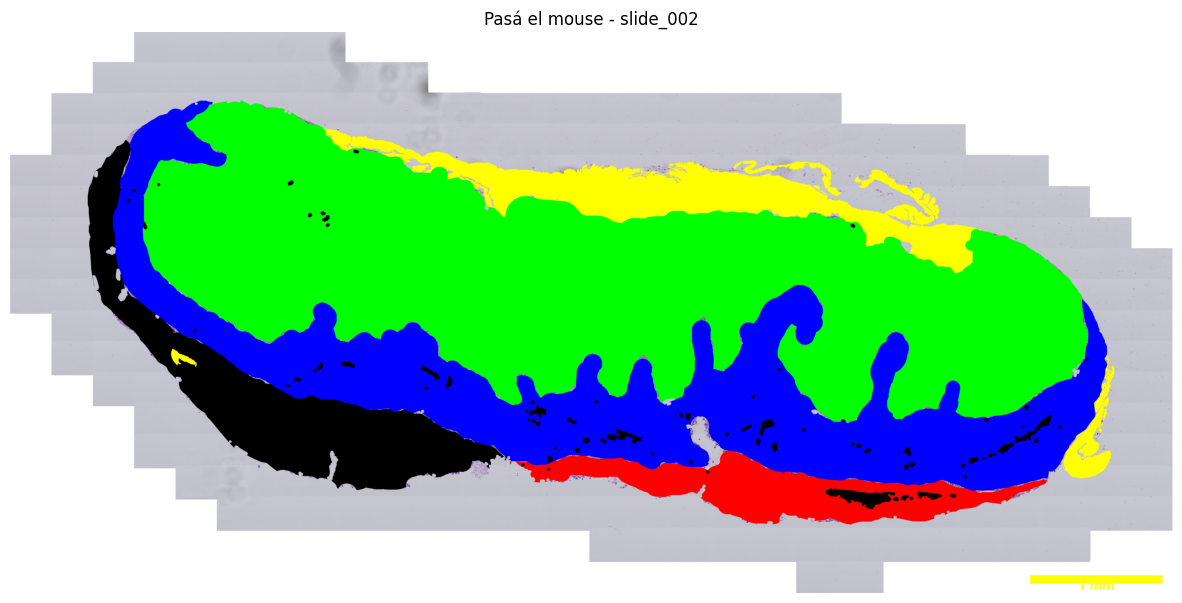

Ejecutar esta celda y pasar el mouse por encima de la imagen.


In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.backend_bases import MouseEvent

fig, ax = plt.subplots(figsize=(15, 12))
ax.imshow(overlay)
ax.set_title(f'Pasá el mouse - {slide_id}')
ax.axis('off')

info_text = ax.text(0.02, 0.98, '', transform=ax.transAxes, fontsize=12,
                    verticalalignment='top', color='white',
                    bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))

def on_mouse_move(event: MouseEvent):
    if event.inaxes == ax:
        x, y = int(event.xdata), int(event.ydata)
        clase = get_class_at_pixel(class_mask, class_names, x, y)
        info_text.set_text(f'Pixel ({x}, {y}): {clase}')
        fig.canvas.draw_idle()

fig.canvas.mpl_connect('motion_notify_event', on_mouse_move)
plt.show()

print("Ejecutar esta celda y pasar el mouse por encima de la imagen.")

## Escanear toda la imagen para encontrar pixels negros
Busca todas las regiones que sevisualizan como negro en la imagen.

Pixels negros en el overlay: 2274010
Porcentaje de la imagen: 4.5943%
Regiones negras encontradas: 81


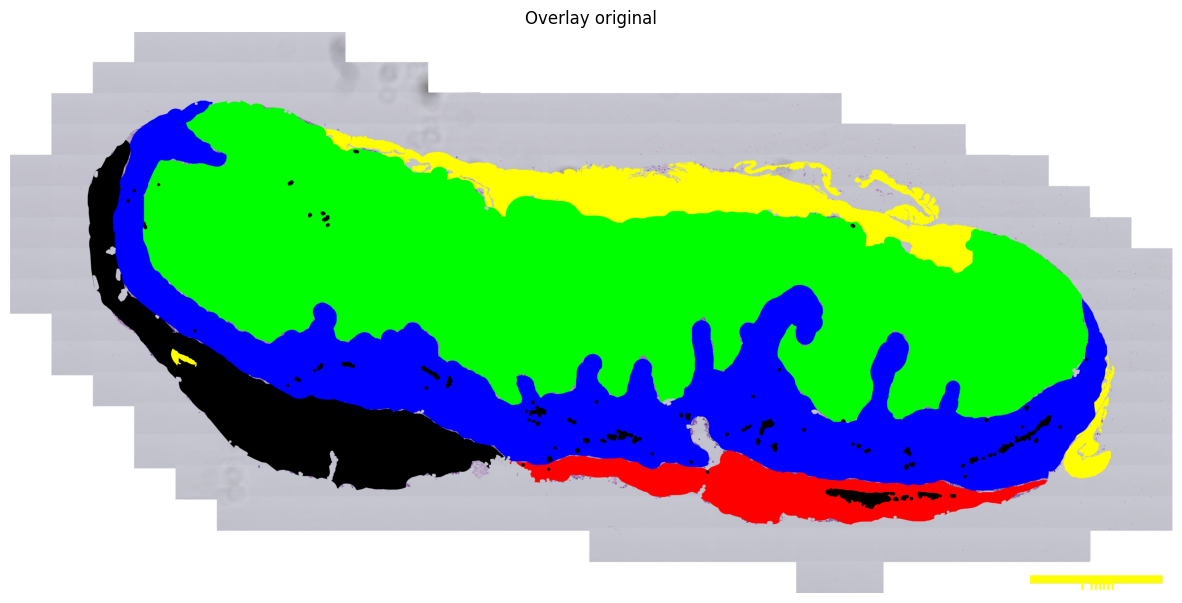

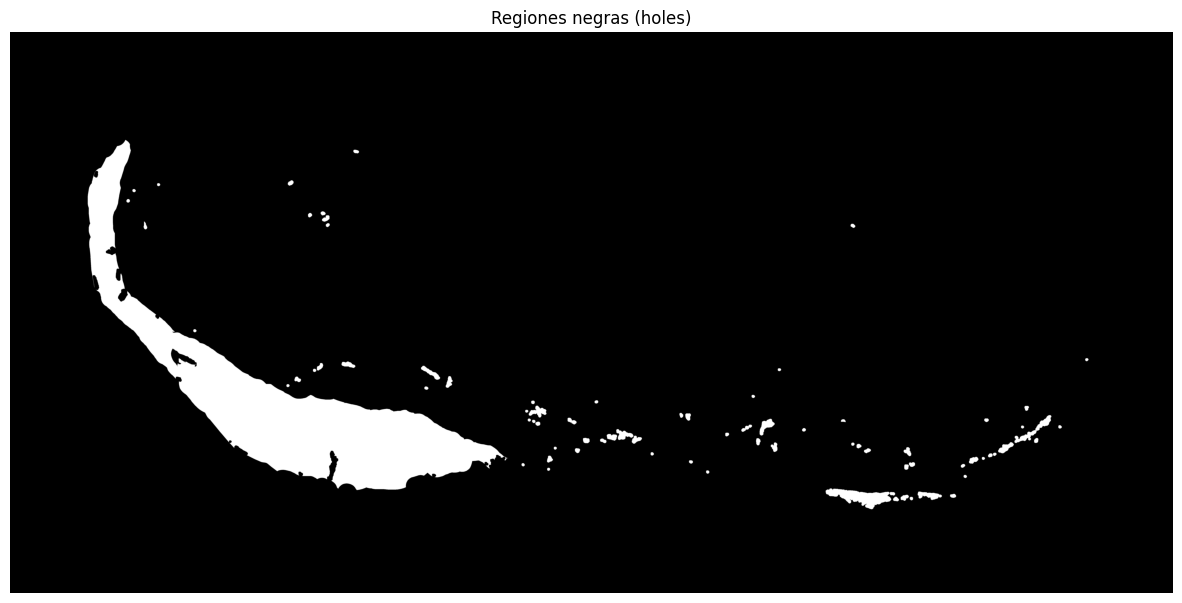

In [11]:
# Escanear la imagen para encontrar regiones que se ven como negro
gray = cv2.cvtColor(overlay, cv2.COLOR_RGB2GRAY)
black_pixels = (gray == 0)
print(f"Pixels negros en el overlay: {np.sum(black_pixels)}")
print(f"Porcentaje de la imagen: {np.sum(black_pixels) / black_pixels.size * 100:.4f}%")

black_mask = (gray == 0).astype(np.uint8) * 255
contours, _ = cv2.findContours(black_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f"Regiones negras encontradas: {len(contours)}")

plt.figure(figsize=(15, 12))
plt.imshow(overlay)
plt.title('Overlay original')
plt.axis('off')
plt.show()

plt.figure(figsize=(15, 12))
plt.imshow(black_mask, cmap='gray')
plt.title('Regiones negras (holes)')
plt.axis('off')
plt.show()

In [19]:
def check_overlapping_annotations(annotations, img_shape):
    """
    Verifica si hay pixeles con más de una anotación.
    
    Returns:
    - overlappings: lista de tuplas (x, y, clase1, clase2) con pixeles duplicados
    - overlap_mask: máscara binaria donde hay solapamiento
    """
    h, w = img_shape[:2]
    
    # Bitmap para tracking de primeiro dibujado de cada feature
    first_draw = np.zeros((h, w), dtype=np.uint8)
    
    overlappings = []
    overlap_mask = np.zeros((h, w), dtype=np.uint8)
    
    class_names = []
    for idx, feature in enumerate(annotations['features']):
        class_name = feature['properties'].get('name', 'unknown')
        class_names.append(class_name)
        
        geom = shape(feature['geometry'])
        
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        # Crear mask temporal para esta feature
        temp_mask = np.zeros((h, w), dtype=np.uint8)
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(temp_mask, [ext_coords], 1)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(temp_mask, [int_coords], 0)
        
        # Contar cuántos pixels ya estaban annotateados
        already_drawn = np.logical_and(first_draw, temp_mask)
        
        if np.any(already_drawn):
            # Encontrar alguns pixels duplicados
            coords = np.where(already_drawn)
            # Tomar una muestra (no todos para no saturar)
            n_sample = min(100, len(coords[0]))
            for i in range(n_sample):
                y, x = coords[0][i], coords[1][i]
                # Encontrar qué clase estava ahí
                prev_class = None
                for j in range(idx):
                    prev_feature = annotations['features'][j]
                    prev_class_name = prev_feature['properties'].get('name', 'unknown')
                    prev_geom = shape(prev_feature['geometry'])
                    
                    if prev_geom.geom_type == 'Polygon':
                        prev_polys = [prev_geom]
                    elif prev_geom.geom_type == 'MultiPolygon':
                        prev_polys = list(prev_geom.geoms)
                    else:
                        continue
                    
                    for pp in prev_polys:
                        if pp.contains(geom.Point(x, y)):
                            prev_class = prev_class_name
                            break
                    
                    if prev_class:
                        break
                
                overlappings.append((x, y, prev_class, class_name))
            
            # Marcar en overlap_mask
            overlap_mask = np.logical_or(overlap_mask, already_drawn).astype(np.uint8)
        
        # Acumular para próxiima iteración
        first_draw = np.logical_or(first_draw, temp_mask).astype(np.uint8)
    
    # Resumen
    total_overlaps = np.sum(overlap_mask)
    print(f"Pixeles con solapamiento: {total_overlaps}")
    print(f"Porcentaje de la imágen: {total_overlaps / overlap_mask.size * 100:.4f}%")
    
    if total_overlaps > 0:
        print(f"\nEjemplos de solapamiento (primeros 10):")
        for i, (x, y, c1, c2) in enumerate(overlappings[:10]):
            print(f"  Pixel ({x}, {y}): {c1} <-> {c2}")
    
    return overlappings, overlap_mask

In [20]:
# Verificar solapamientos
overlappings, overlap_mask = check_overlapping_annotations(annotations, img.shape)

AttributeError: 'MultiPolygon' object has no attribute 'Point'

In [12]:
# Mostrar dónde están los solapamientos
if np.any(overlap_mask):
    plt.figure(figsize=(15, 12))
    plt.imshow(img_rgb)
    plt.imshow(overlap_mask, cmap='Reds', alpha=0.5)
    plt.title('Regiones con solapamiento (rojo)')
    plt.axis('off')
    plt.show()
else:
    print("No hay solapamientos. Todas las anotaciones están bien separadas.")